In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *


%config InlineBackend.figure_format ='retina'


header_setting.py: using old naming


# Simulated data sets

In [4]:
# # get files

directory = '../../data_realtrace_paper/glucose_hi1_simulation1000_adder_wo_bleaching/glucose_hi1_simulation1000_adder_wo_bleaching_0/'
sample = directory.split("/")[-2]


noisy_data = pd.read_csv(directory + sample + ".csv",dtype={"parent_id":str, "cell_id":str})

cells_noise = df2cells(noisy_data, time="time_min", log_length="log_length_noise", gfp="gfp_noise", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")

cells_true_samples = df2cells(noisy_data, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")
# noisy_data["cell_id"] = noisy_data["lane"].astype(str) + '.' + noisy_data["cell_id"].astype(str)
# noisy_data["parent_id"] = noisy_data["lane"].astype(str) + '.' + noisy_data["parent_id"].astype(str)


full_data = pd.read_csv(directory + sample + "_full.csv",dtype={"parent_id":str, "cell_id":str})

cells_true = df2cells(full_data, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")


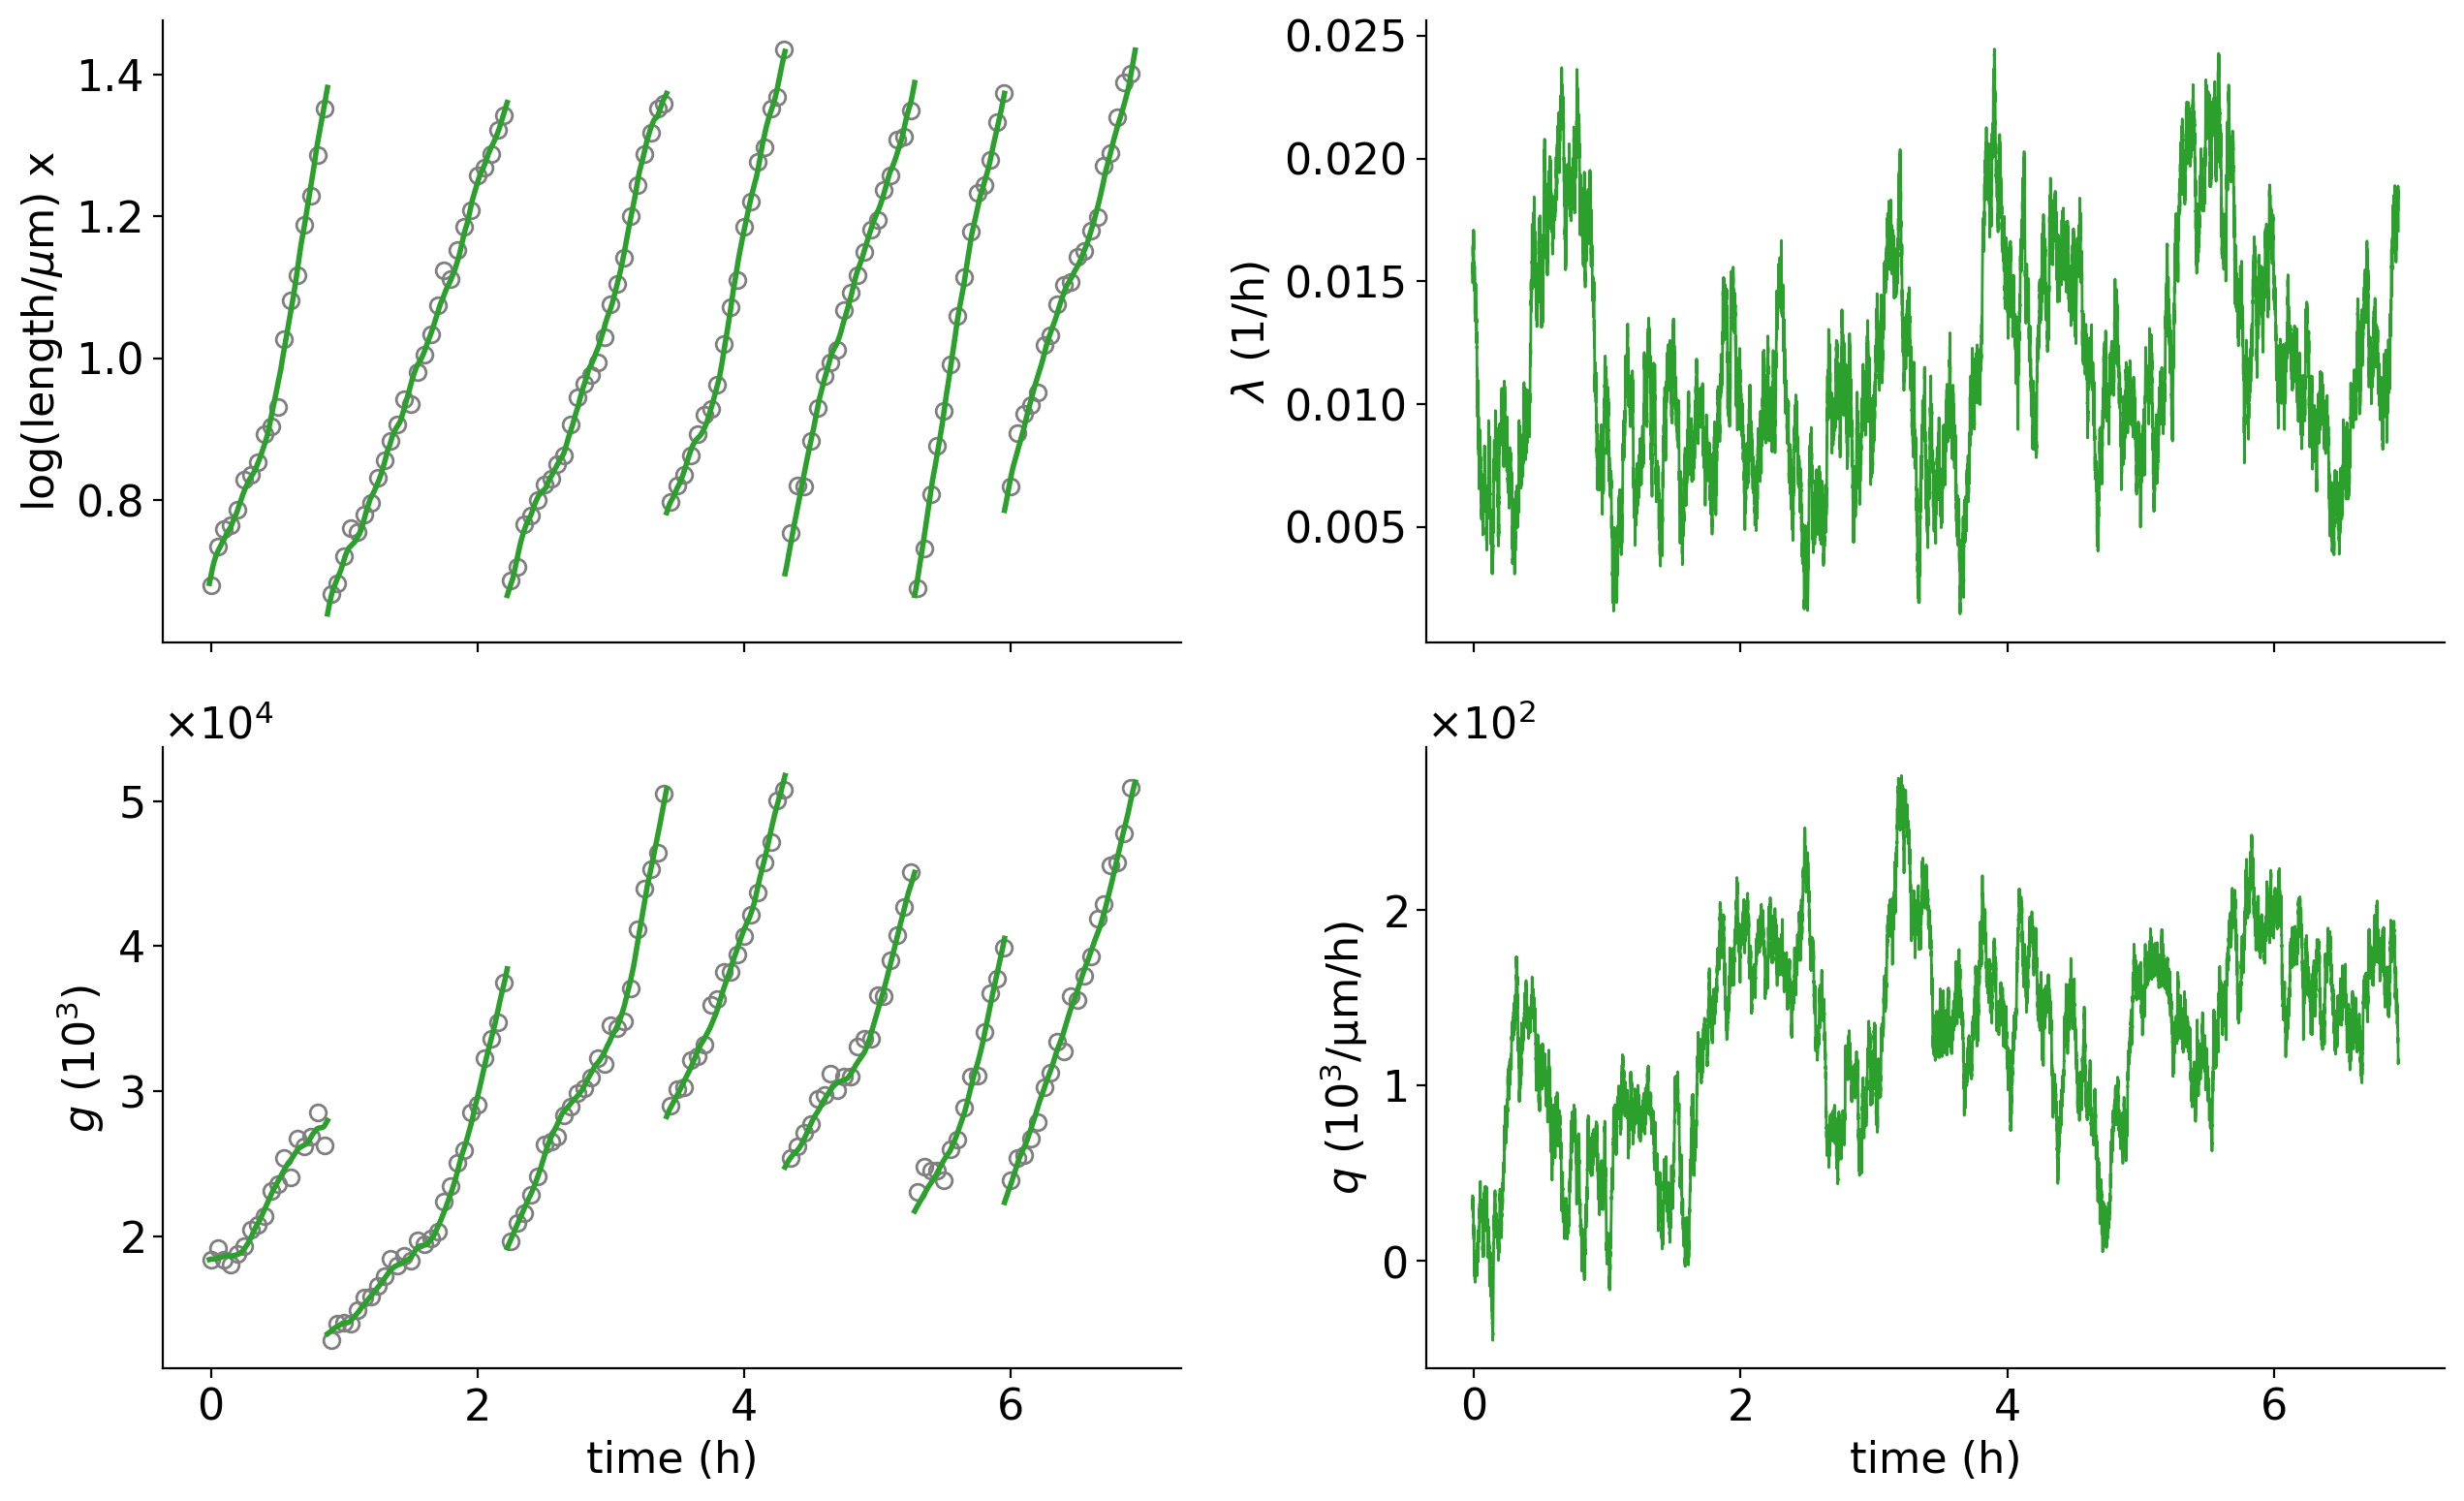

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>],
      dtype=object)

In [5]:
def plot_raw_and_true(cells_noisy, cells_true, cell_idx, time_unit=("h", 60), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
        
    fig, axes = plt.subplots(2, 2, figsize=(FULL_SIZE,FULL_HEIGHT*2), sharex=True)
    # fig, axes = plt.subplots(1,4, figsize=(16,4), sharex=True)

    axes = axes.transpose()
    ax = axes.ravel()

    s = 10
    lw = 1.5
        
    color_true = "tab:green"
    t0 = cells_noisy[cell_idx[0]].time[0]/time_unit[1]
    for _, i in enumerate(cell_idx):
        
        # "Data"
        p0a = ax[0].plot(np.array(cells_noisy[i].time)/time_unit[1]-t0, cells_noisy[i].log_length, 
                         'o', markersize=6, mfc='none', color="tab:grey", alpha=1)[0]
        
        p1a = ax[1].plot(np.array(cells_noisy[i].time)/time_unit[1]-t0, cells_noisy[i].gfp, 
                         'o', markersize=6, mfc='none', color="tab:grey", alpha=1)[0]

        # Truth
        p0b = ax[0].plot(np.array(cells_true[i].time)/time_unit[1]-t0, 
                         cells_true[i].log_length, color=color_true, lw=2)[0]
        p1b = ax[1].plot(np.array(cells_true[i].time)/time_unit[1]-t0, 
                         cells_true[i].gfp, color=color_true, lw=2)[0]

        p2 = ax[2].plot(np.array(cells_true[i].time)/time_unit[1]-t0, 
                        cells_true[i].lt, color=color_true, lw=1)[0]
        p3 = ax[3].plot(np.array(cells_true[i].time)/time_unit[1]-t0, 
                        cells_true[i].qt, color=color_true, lw=1)[0]

    for i in range(4):
        ax[i].set_xlim(xlim)


    ax[0].set_ylabel("log(length/$\mu$m) x")  
    ax[1].set_ylabel("$g$ ($10^3$)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(10^3/\mu m/h)}$")   

    ax[1].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[3].set_xlabel("time ({:s})".format(time_unit[0]))  
    
    ax[1].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)
    ax[3].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)

    ax2_lim = ax[2].get_ylim()
    ax3_lim = ax[3].get_ylim()


        
    ax[2].set_ylim(ax2_lim)
    ax[3].set_ylim(ax3_lim)
    fig.tight_layout()
    
    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax

plot_raw_and_true(cells_noise, cells_true, get_longest_path(cells_noise)[:7],
                  outfile="../../figures_for_method_paper/supp/simulated_trace.pdf")